Loading Munich FleetPy Results...
=== TEMPORAL ANALYSIS ===


/var/folders/g8/7dsc7c7d5757b7m6xbqnwy680000gn/T/ipykernel_58724/1379335296.py:22: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  user_ts = users.set_index('time').resample(f'{interval_minutes}T').agg({
/var/folders/g8/7dsc7c7d5757b7m6xbqnwy680000gn/T/ipykernel_58724/1379335296.py:29: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  util = ops.groupby(pd.Grouper(key='time', freq=f'{interval_minutes}T')).occupied.mean() * 100
/var/folders/g8/7dsc7c7d5757b7m6xbqnwy680000gn/T/ipykernel_58724/1379335296.py:22: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  user_ts = users.set_index('time').resample(f'{interval_minutes}T').agg({
/var/folders/g8/7dsc7c7d5757b7m6xbqnwy680000gn/T/ipykernel_58724/1379335296.py:29: FutureWarning: 'T' is deprecated and will be removed in a future version, please use 'min' instead.
  util = ops.groupby(p

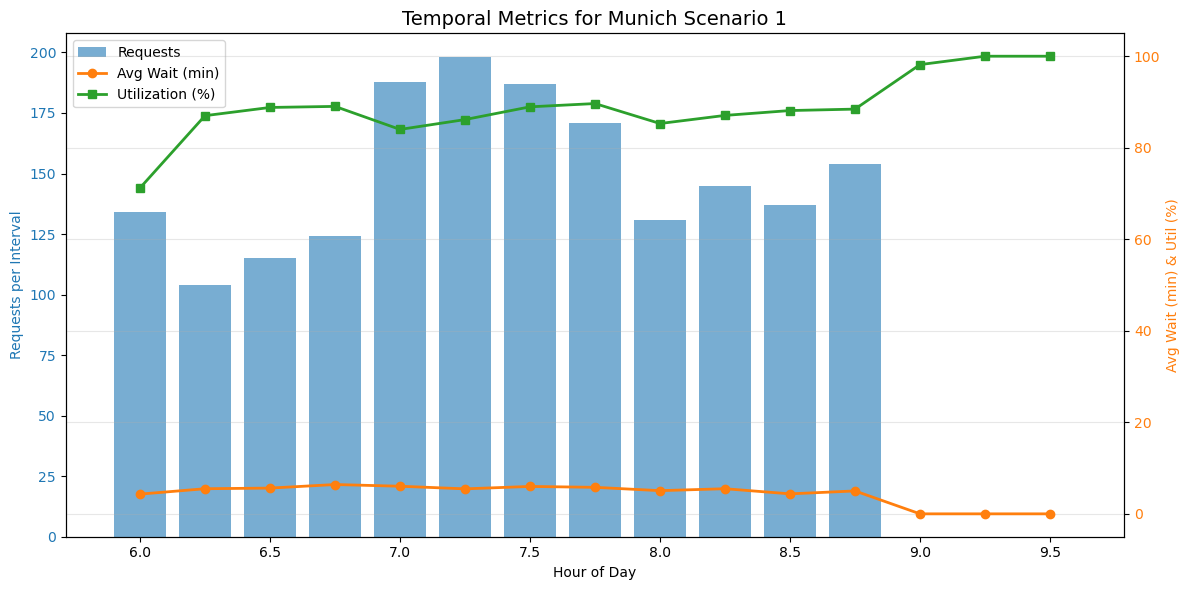

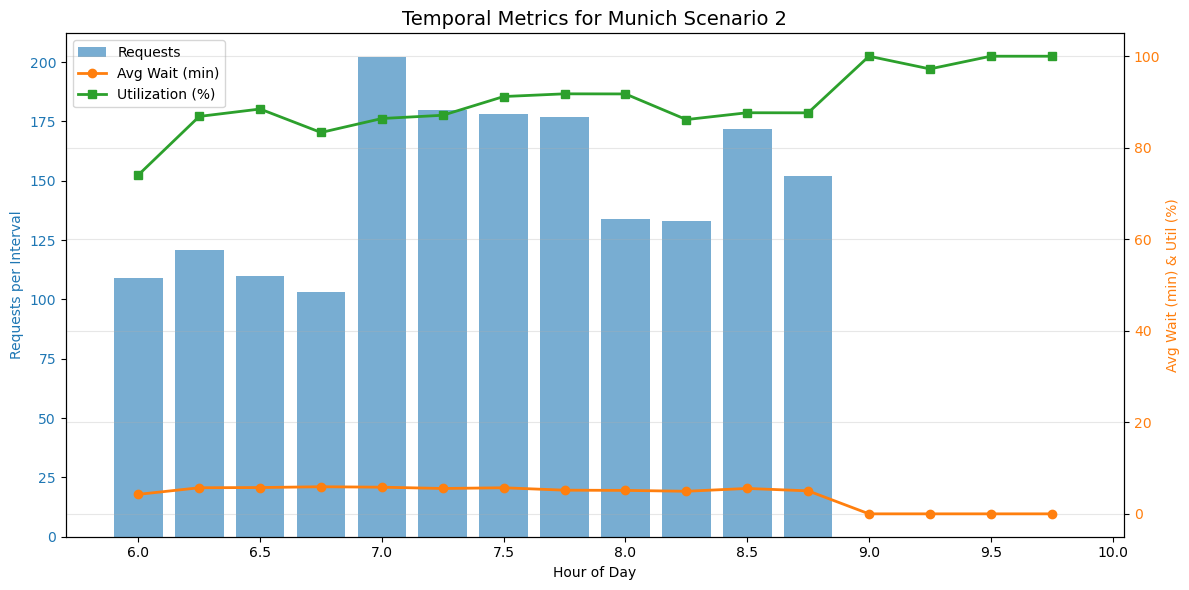


=== SCENARIO 1 SUMMARY ===
Total trips: 1,788
Average waiting time: 5.3 minutes
Max waiting time: 19.0 minutes
Service rate (≤10 min wait): 35.3%
Unique vehicles: 50

=== SCENARIO 2 SUMMARY ===
Total trips: 1,771
Average waiting time: 5.3 minutes
Max waiting time: 13.3 minutes
Service rate (≤10 min wait): 35.6%
Unique vehicles: 50

=== COMPARATIVE ANALYSIS ===


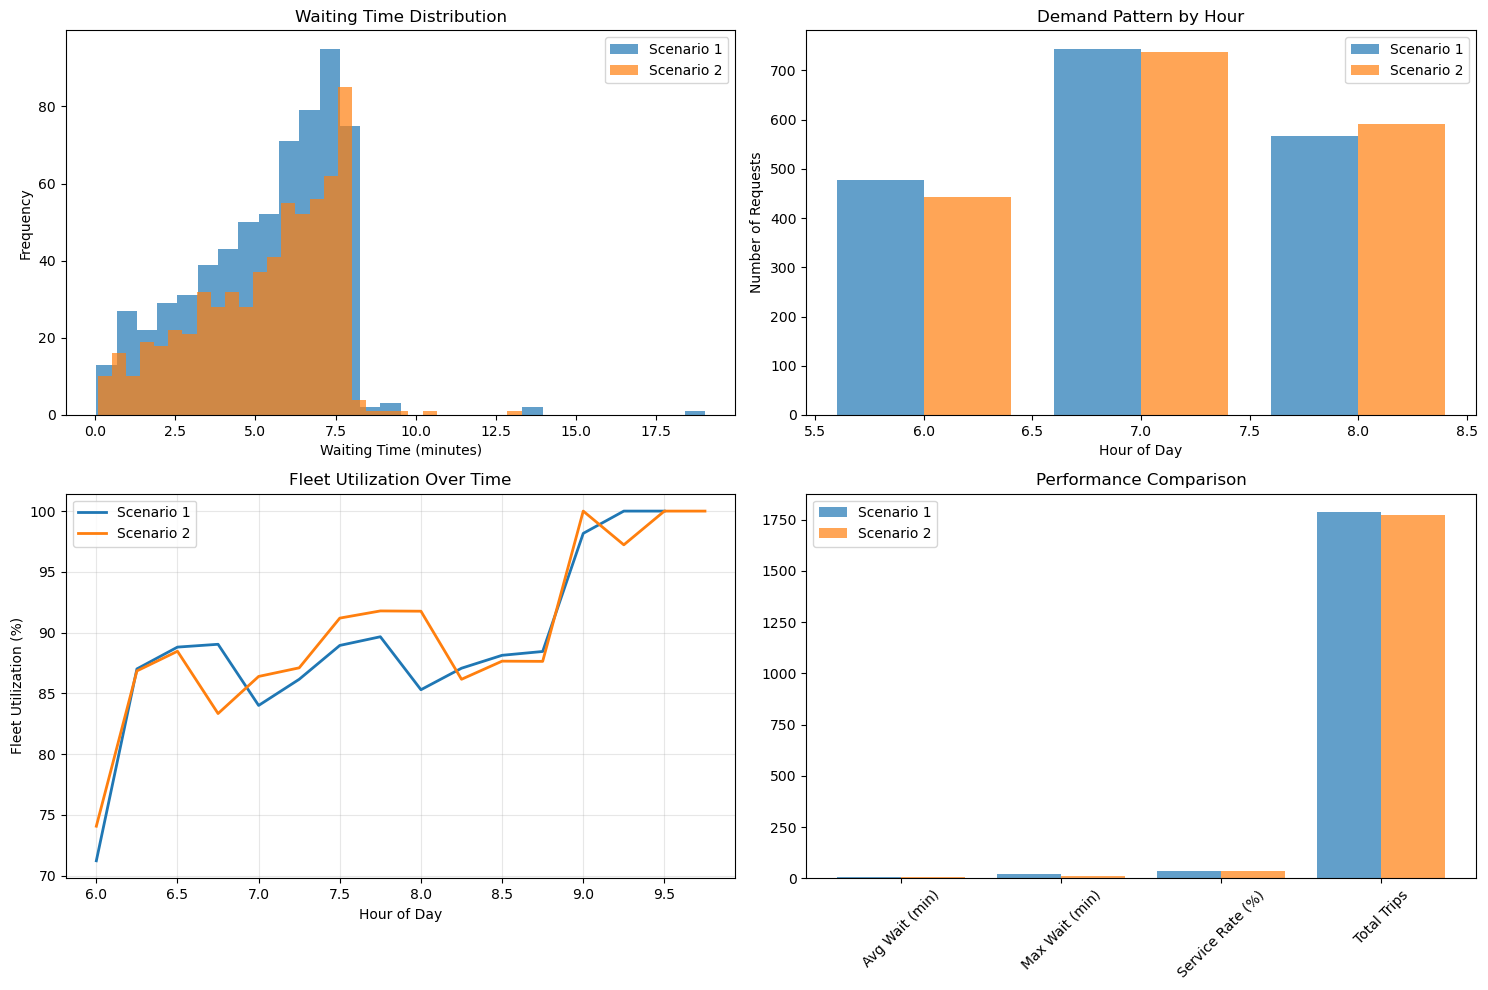


=== MUNICH SCENARIOS COMPARISON TABLE ===
                 Metric  Scenario 1  Scenario 2
            Total Trips      1788.0      1771.0
    Avg Wait Time (min)         5.3         5.3
    Max Wait Time (min)        19.0        13.3
Service Rate ≤10min (%)        35.3        35.6
        Unique Vehicles        50.0        50.0
       Peak Hour Demand       744.0       737.0

Summary saved to: munich_scenarios_comparison.csv

=== KEY INSIGHTS ===
• Scenario 2 has better average waiting times
• Peak demand occurs around hour 7.0 for Scenario 1, hour 7.0 for Scenario 2
• Fleet utilization peaks: Scenario 1 = 100.0%, Scenario 2 = 100.0%


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

# Function definitions
def load_data(result_dir):
    """Load user and operations data from FleetPy results directory"""
    users = pd.read_csv(os.path.join(result_dir, '1_user-stats.csv'))
    ops   = pd.read_csv(os.path.join(result_dir, '2-0_op-stats.csv'))
    return users, ops

def aggregate_temporal(users, ops, interval_minutes=15):
    """Aggregate metrics by time intervals"""
    # Compute waiting time (pickup_time - rq_time)
    users['waiting_time'] = users['pickup_time'] - users['rq_time']

    # Convert request_time and op start_time to timedelta for resampling
    users['time'] = pd.to_timedelta(users['rq_time'], unit='s')
    ops['time']   = pd.to_timedelta(ops['start_time'], unit='s')

    # Aggregate user metrics per interval
    user_ts = users.set_index('time').resample(f'{interval_minutes}T').agg({
        'request_id': 'count',
        'waiting_time': 'mean'
    }).rename(columns={'request_id':'requests','waiting_time':'avg_wait_s'})

    # Fleet utilization: % of vehicles with occupancy>0 per interval
    ops['occupied'] = ops['occupancy'] > 0
    util = ops.groupby(pd.Grouper(key='time', freq=f'{interval_minutes}T')).occupied.mean() * 100
    util_ts = util.rename('util_pct')

    # Combine into one DataFrame
    df = pd.concat([user_ts, util_ts], axis=1).fillna(0)
    return df

def plot_temporal(df, scenario_name):
    """Create temporal analysis plot"""
    fig, ax1 = plt.subplots(figsize=(12, 6))

    # Bar: requests per interval
    width = df.index.freq.delta.total_seconds() / 3600 * 0.8
    ax1.bar(df.index.total_seconds()/3600, df.requests,
            width=width, color='C0', alpha=0.6, label='Requests')
    ax1.set_xlabel('Hour of Day')
    ax1.set_ylabel('Requests per Interval', color='C0')
    ax1.tick_params(axis='y', labelcolor='C0')

    # Line: avg waiting time and utilization
    ax2 = ax1.twinx()
    ax2.plot(df.index.total_seconds()/3600, df.avg_wait_s/60,
             'C1-o', label='Avg Wait (min)', linewidth=2)
    ax2.plot(df.index.total_seconds()/3600, df.util_pct,
             'C2-s', label='Utilization (%)', linewidth=2)
    ax2.set_ylabel('Avg Wait (min) & Util (%)', color='C1')
    ax2.tick_params(axis='y', labelcolor='C1')

    # Combined legend
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    ax1.legend(lines1+lines2, labels1+labels2, loc='upper left')

    plt.title(f'Temporal Metrics for {scenario_name}', fontsize=14)
    plt.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()

    return fig

# Load and analyze both scenarios
print("Loading Munich FleetPy Results...")

# Scenario 1
scenario1_dir = 'studies/munich_case_study/results/test_munich_scenario_1'
users1, ops1 = load_data(scenario1_dir)
df1 = aggregate_temporal(users1, ops1, interval_minutes=15)

# Scenario 2
scenario2_dir = 'studies/munich_case_study/results/test_munich_scenario_2'
users2, ops2 = load_data(scenario2_dir)
df2 = aggregate_temporal(users2, ops2, interval_minutes=15)

# Display individual scenario plots
print("=== TEMPORAL ANALYSIS ===")
fig1 = plot_temporal(df1, 'Munich Scenario 1')
fig2 = plot_temporal(df2, 'Munich Scenario 2')

# Print summary statistics
print("\n=== SCENARIO 1 SUMMARY ===")
print(f"Total trips: {len(users1):,}")
print(f"Average waiting time: {users1['waiting_time'].mean()/60:.1f} minutes")
print(f"Max waiting time: {users1['waiting_time'].max()/60:.1f} minutes")
print(f"Service rate (≤10 min wait): {(users1['waiting_time'] <= 600).mean()*100:.1f}%")
print(f"Unique vehicles: {ops1['vehicle_id'].nunique()}")

print("\n=== SCENARIO 2 SUMMARY ===")
print(f"Total trips: {len(users2):,}")
print(f"Average waiting time: {users2['waiting_time'].mean()/60:.1f} minutes")
print(f"Max waiting time: {users2['waiting_time'].max()/60:.1f} minutes")
print(f"Service rate (≤10 min wait): {(users2['waiting_time'] <= 600).mean()*100:.1f}%")
print(f"Unique vehicles: {ops2['vehicle_id'].nunique()}")

# Create comprehensive comparison visualization
print("\n=== COMPARATIVE ANALYSIS ===")
fig, ((ax1, ax2), (ax3, ax4)) = plt.subplots(2, 2, figsize=(15, 10))

# Waiting time distributions
ax1.hist(users1['waiting_time']/60, bins=30, alpha=0.7, label='Scenario 1', color='C0')
ax1.hist(users2['waiting_time']/60, bins=30, alpha=0.7, label='Scenario 2', color='C1')
ax1.set_xlabel('Waiting Time (minutes)')
ax1.set_ylabel('Frequency')
ax1.set_title('Waiting Time Distribution')
ax1.legend()

# Request patterns by hour
users1['hour'] = users1['rq_time'] // 3600
users2['hour'] = users2['rq_time'] // 3600
hourly1 = users1.groupby('hour').size()
hourly2 = users2.groupby('hour').size()

ax2.bar(hourly1.index - 0.2, hourly1.values, width=0.4, alpha=0.7, label='Scenario 1', color='C0')
ax2.bar(hourly2.index + 0.2, hourly2.values, width=0.4, alpha=0.7, label='Scenario 2', color='C1')
ax2.set_xlabel('Hour of Day')
ax2.set_ylabel('Number of Requests')
ax2.set_title('Demand Pattern by Hour')
ax2.legend()

# Fleet utilization over time
ax3.plot(df1.index.total_seconds()/3600, df1.util_pct, label='Scenario 1', linewidth=2, color='C0')
ax3.plot(df2.index.total_seconds()/3600, df2.util_pct, label='Scenario 2', linewidth=2, color='C1')
ax3.set_xlabel('Hour of Day')
ax3.set_ylabel('Fleet Utilization (%)')
ax3.set_title('Fleet Utilization Over Time')
ax3.legend()
ax3.grid(True, alpha=0.3)

# Performance metrics comparison
metrics = ['Avg Wait (min)', 'Max Wait (min)', 'Service Rate (%)', 'Total Trips']
values1 = [users1['waiting_time'].mean()/60,
           users1['waiting_time'].max()/60,
           (users1['waiting_time'] <= 600).mean()*100,
           len(users1)]
values2 = [users2['waiting_time'].mean()/60,
           users2['waiting_time'].max()/60,
           (users2['waiting_time'] <= 600).mean()*100,
           len(users2)]

x = range(len(metrics))
ax4.bar([i-0.2 for i in x], values1, width=0.4, alpha=0.7, label='Scenario 1', color='C0')
ax4.bar([i+0.2 for i in x], values2, width=0.4, alpha=0.7, label='Scenario 2', color='C1')
ax4.set_xticks(x)
ax4.set_xticklabels(metrics, rotation=45)
ax4.set_title('Performance Comparison')
ax4.legend()

plt.tight_layout()
plt.show()

# Create and display summary comparison table
summary = pd.DataFrame({
    'Metric': ['Total Trips', 'Avg Wait Time (min)', 'Max Wait Time (min)',
               'Service Rate ≤10min (%)', 'Unique Vehicles', 'Peak Hour Demand'],
    'Scenario 1': [
        len(users1),
        round(users1['waiting_time'].mean()/60, 1),
        round(users1['waiting_time'].max()/60, 1),
        round((users1['waiting_time'] <= 600).mean()*100, 1),
        ops1['vehicle_id'].nunique(),
        hourly1.max()
    ],
    'Scenario 2': [
        len(users2),
        round(users2['waiting_time'].mean()/60, 1),
        round(users2['waiting_time'].max()/60, 1),
        round((users2['waiting_time'] <= 600).mean()*100, 1),
        ops2['vehicle_id'].nunique(),
        hourly2.max()
    ]
})

print("\n=== MUNICH SCENARIOS COMPARISON TABLE ===")
print(summary.to_string(index=False))

# Save summary for presentation
summary.to_csv('munich_scenarios_comparison.csv', index=False)
print(f"\nSummary saved to: munich_scenarios_comparison.csv")

print("\n=== KEY INSIGHTS ===")
better_scenario = 1 if users1['waiting_time'].mean() < users2['waiting_time'].mean() else 2
print(f"• Scenario {better_scenario} has better average waiting times")
print(f"• Peak demand occurs around hour {hourly1.idxmax()} for Scenario 1, hour {hourly2.idxmax()} for Scenario 2")
print(f"• Fleet utilization peaks: Scenario 1 = {df1.util_pct.max():.1f}%, Scenario 2 = {df2.util_pct.max():.1f}%")
